<a href="https://colab.research.google.com/github/chitkala07/Student-data/blob/main/ml_notebook_2_student_pass.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 2: Messy Data, Preprocessing and Prediction
**Hands-on Machine Learning: From Data Preprocessing to Predictive Model Building**
Dr. Ayesha Mukthar | AlMoosa College of Health Sciences | ACM-W Stanley Student Chapter

A **synthetic** student dataset with missing values and categories. Use it only for learning, never for real academic decisions.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
sns.set_theme(style="whitegrid")

## Step 1: Create the dataset
Target `pass`: 1 = pass, 0 = not pass. Student ID is an identifier, not a feature. (You can also save it with `df.to_csv` and re-upload it as practice.)

In [ ]:
rng = np.random.default_rng(42)
n = 600
df = pd.DataFrame({
    "student_id": range(1001, 1001 + n),
    "study_hours": rng.gamma(4, 1.2, n).round(1),
    "missed_classes": rng.poisson(3, n),
    "previous_score": rng.normal(65, 12, n).round(0),
    "internet_access": rng.choice(["yes", "no"], n, p=[0.8, 0.2]),
})
logit = -6 + 0.45*df.study_hours - 0.25*df.missed_classes + 0.07*df.previous_score + 0.5*(df.internet_access == "yes")
df["pass"] = (rng.random(n) < 1/(1 + np.exp(-logit))).astype(int)
# make the data messy
for col, frac in [("study_hours", 0.08), ("previous_score", 0.06), ("internet_access", 0.05)]:
    df.loc[rng.choice(n, int(frac*n), replace=False), col] = np.nan
df = pd.concat([df, df.sample(10, random_state=1)])   # add duplicate rows
print(df.shape); df.head()

(610, 6)


,student_id,study_hours,missed_classes,previous_score,internet_access,pass
0,1001,5.1,1,56.0,NaN,0
1,1002,6.4,3,51.0,yes,1
2,1003,4.7,1,77.0,no,1
3,1004,NaN,2,45.0,yes,1
4,1005,6.7,3,76.0,yes,1


## Step 2-3: Inspect and clean

In [ ]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Pass rate: %.2f" % df["pass"].mean())
df.describe()

student_id          0
study_hours        48
missed_classes      0
previous_score     37
internet_access    30
pass                0
dtype: int64
Duplicates: 10
Pass rate: 0.58


,student_id,study_hours,missed_classes,previous_score,pass
count,600.000000,552.000000,600.000000,564.000000,600.000000
mean,1300.500000,4.778261,3.008333,64.657801,0.581667
std,173.349358,2.359019,1.797308,11.746203,0.493697
min,1001.000000,0.800000,0.000000,33.000000,0.000000
25%,1150.750000,3.100000,2.000000,56.000000,0.000000
50%,1300.500000,4.400000,3.000000,64.000000,1.000000
75%,1450.250000,6.100000,4.000000,72.000000,1.000000
max,1600.000000,16.500000,9.000000,106.000000,1.000000


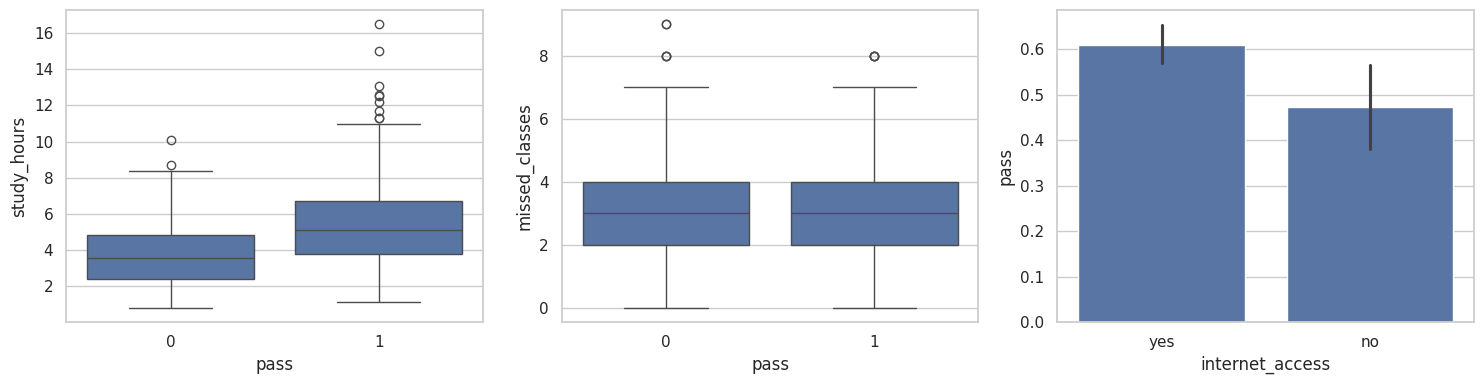

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x="pass", y="study_hours", ax=ax[0])
sns.boxplot(data=df, x="pass", y="missed_classes", ax=ax[1])
sns.barplot(data=df, x="internet_access", y="pass", ax=ax[2])
plt.tight_layout(); plt.show()

**Checkpoint:** which feature looks most related to passing?

## Step 4: Split before preprocessing
We drop `student_id` and keep the rest.

In [ ]:
X = df.drop(columns=["pass", "student_id"]); y = df["pass"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
num = ["study_hours", "missed_classes", "previous_score"]; cat = ["internet_access"]

## Step 5: Preprocessing pipeline
Impute (median for numbers, most frequent for categories), scale numbers, one-hot encode categories. All fitted on training data only.

In [ ]:
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
])
logreg = Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=1000))])
forest = Pipeline([("prep", prep), ("model", RandomForestClassifier(n_estimators=200, random_state=42))])
for name, m in [("Logistic Regression", logreg), ("Random Forest", forest)]:
    m.fit(Xtr, ytr)
    print(name, "test accuracy: %.3f" % m.score(Xte, yte))

Logistic Regression test accuracy: 0.700
Random Forest test accuracy: 0.700


## Step 6: Evaluate
For an early-support programme, **recall of the 'not pass' class** matters: we do not want to miss students who need help.

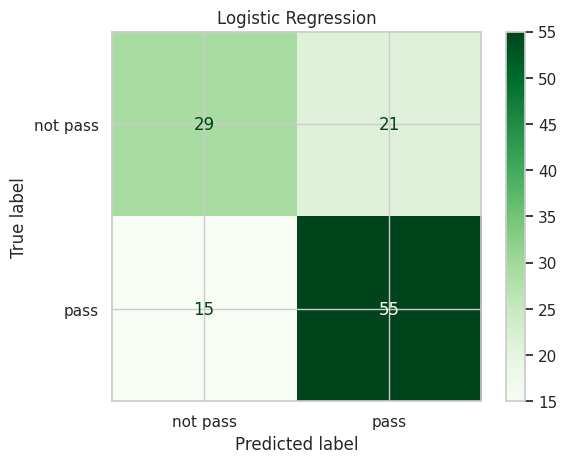

              precision    recall  f1-score   support

    not pass       0.66      0.58      0.62        50
        pass       0.72      0.79      0.75        70

    accuracy                           0.70       120
   macro avg       0.69      0.68      0.69       120
weighted avg       0.70      0.70      0.70       120



In [ ]:
pred = logreg.predict(Xte)
ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=["not pass", "pass"]).plot(cmap="Greens")
plt.title("Logistic Regression"); plt.show()
print(classification_report(yte, pred, target_names=["not pass", "pass"]))

In [ ]:
for name, m in [("Logistic Regression", logreg), ("Random Forest", forest)]:
    s = cross_val_score(m, X, y, cv=5)
    print(f"{name}: 5-fold CV accuracy {s.mean():.3f} (+/- {s.std():.3f})")

Logistic Regression: 5-fold CV accuracy 0.730 (+/- 0.012)
Random Forest: 5-fold CV accuracy 0.680 (+/- 0.027)


## Improve: tune the forest

In [ ]:
grid = GridSearchCV(forest, {"model__max_depth": [3, 5, None], "model__min_samples_leaf": [1, 3, 5]}, cv=5, scoring="f1", n_jobs=-1)
grid.fit(Xtr, ytr)
print("Best:", grid.best_params_, " Test accuracy: %.3f" % grid.score(Xte, yte))

Best: {'model__max_depth': 3, 'model__min_samples_leaf': 1}  Test accuracy: 0.769


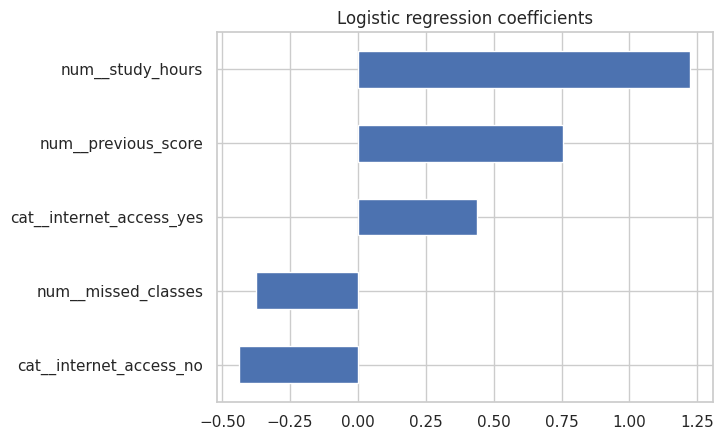

In [ ]:
coefs = pd.Series(logreg.named_steps["model"].coef_[0], index=logreg.named_steps["prep"].get_feature_names_out()).sort_values()
coefs.plot(kind="barh", title="Logistic regression coefficients"); plt.show()

## Mini-challenge and reflection
1. Add `student_id` as a feature and see what a random forest does (why is this wrong?).
2. Change the split or remove `internet_access`.
3. Compare precision and recall for the 'not pass' class.
4. **Discuss:** what harm could a wrong prediction cause, and what human oversight is needed?

*This dataset is artificial and must not be used for real academic decisions.*

In [ ]:
# 1. Prepare data including student_id as a feature
X_id = df.drop(columns=["pass"])
y_id = df["pass"]

Xtr_id, Xte_id, ytr_id, yte_id = train_test_split(
    X_id, y_id, test_size=0.2, stratify=y_id, random_state=42
)

# Defining feature lists
num_id = ["student_id", "study_hours", "missed_classes", "previous_score"]
cat_id = ["internet_access"]

# 2. Update pipeline to include student_id in numerical features
prep_id = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_id),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_id),
])

logreg_id = Pipeline([("prep", prep_id), ("model", LogisticRegression(max_iter=1000))])
forest_id = Pipeline([("prep", prep_id), ("model", RandomForestClassifier(n_estimators=200, random_state=42))])

# 3. Fit and evaluate
for name, m in [("Logistic Regression (with student_id)", logreg_id), ("Random Forest (with student_id)", forest_id)]:
    m.fit(Xtr_id, ytr_id)
    print(name, "test accuracy: %.3f" % m.score(Xte_id, yte_id))

Logistic Regression (with student_id) test accuracy: 0.675
Random Forest (with student_id) test accuracy: 0.675
